# QM9 — HOMO-LUMO gap distribution

Exploratory look at the QM9 pool that use-case 1 seeds are drawn from
(`configs/homo_lumo.yaml`). The window is set by `TARGET_LO`/`TARGET_HI` below,
currently **3.0-4.0 eV**.

Data: `data/seeds/qm9.csv` (gitignored; `data/seeds/README.md` has the download command).
QM9 gaps are **B3LYP/6-31G(2df,p)** and stored in **Hartree**.

Note this is a different basis from the `B3LYP/def2-SVP` in the run config, so QM9 labels
and MolCurator's own VALIDATE numbers are close but not identical.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
from rdkit import Chem, RDLogger

RDLogger.DisableLog("rdApp.*")
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

HARTREE_EV = 27.211386
TARGET_LO, TARGET_HI = 3.0, 4.0

qm9 = pd.read_csv("../data/seeds/qm9.csv")
qm9["gap_ev"] = qm9["gap"] * HARTREE_EV
print(f"{len(qm9):,} molecules")
qm9[["mol_id", "smiles", "gap_ev"]].head()

133,885 molecules


,mol_id,smiles,gap_ev
0,gdb_1,C,13.736308
1,gdb_2,N,9.249150
2,gdb_3,O,9.836916
3,gdb_4,C#C,9.118535
4,gdb_5,C#N,10.329442


## Summary statistics

In [2]:
desc = qm9["gap_ev"].describe(percentiles=[0.01, 0.05, 0.25, 0.5, 0.75, 0.95, 0.99])
print(desc.round(3).to_string())

in_window = qm9["gap_ev"].between(TARGET_LO, TARGET_HI)
print(f"\nIn target window {TARGET_LO}-{TARGET_HI} eV: {in_window.sum():,} "
      f"({100 * in_window.mean():.3f}% of QM9)")

count    133885.000
mean          6.833
std           1.293
min           0.669
1%            4.060
5%            4.738
25%           5.886
50%           6.787
75%           7.842
95%           8.887
99%           9.355
max          16.928

In target window 3.0-4.0 eV: 1,014 (0.757% of QM9)


## Distribution

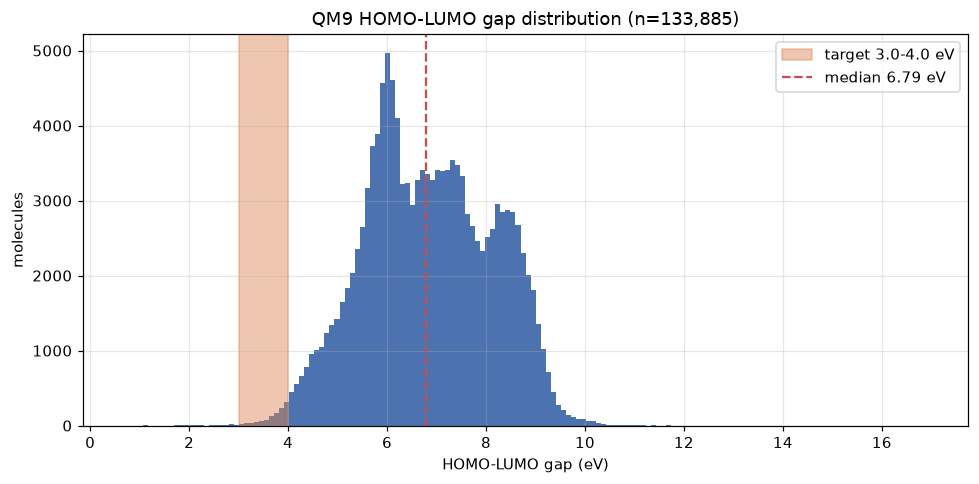

In [3]:
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.hist(qm9["gap_ev"], bins=160, color="#4C72B0", edgecolor="none")
ax.axvspan(TARGET_LO, TARGET_HI, color="#DD8452", alpha=0.45,
           label=f"target {TARGET_LO}-{TARGET_HI} eV")
ax.axvline(qm9["gap_ev"].median(), color="#C44E52", ls="--", lw=1.5,
           label=f"median {qm9['gap_ev'].median():.2f} eV")
ax.set(xlabel="HOMO-LUMO gap (eV)", ylabel="molecules",
       title=f"QM9 HOMO-LUMO gap distribution (n={len(qm9):,})")
ax.legend()
plt.tight_layout()

The target window sits far out in the **lower tail**: QM9 is mostly small, saturated
organics, whose gaps cluster around 6-7 eV. Below, the same data on a log count axis makes
the tail readable.

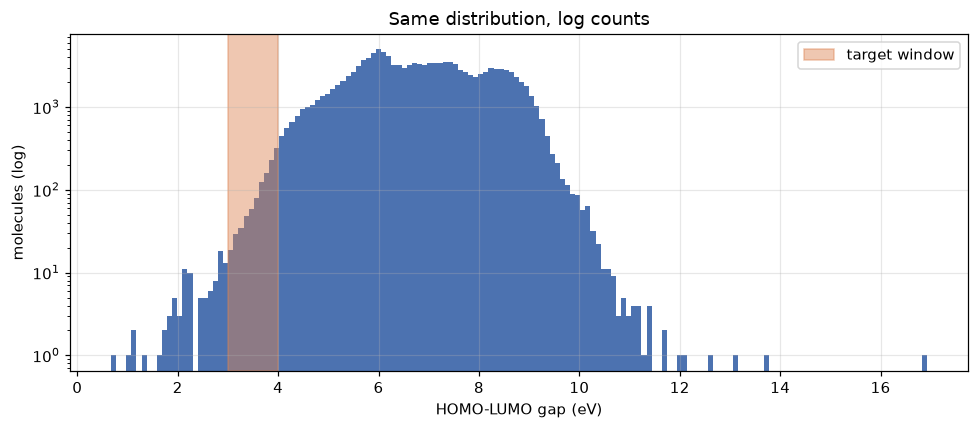

In [4]:
fig, ax = plt.subplots(figsize=(9, 4))
ax.hist(qm9["gap_ev"], bins=160, color="#4C72B0", edgecolor="none")
ax.axvspan(TARGET_LO, TARGET_HI, color="#DD8452", alpha=0.45, label="target window")
ax.set(yscale="log", xlabel="HOMO-LUMO gap (eV)", ylabel="molecules (log)",
       title="Same distribution, log counts")
ax.legend()
plt.tight_layout()

## How many molecules per band

In [5]:
bands = [(0, 2), (2, 3), (3.0, 3.5), (3.5, 4), (4, 5), (5, 6), (6, 7), (7, 20)]
rows = [{"band (eV)": f"{lo}-{hi}",
         "molecules": int(qm9["gap_ev"].between(lo, hi, inclusive="left").sum())}
        for lo, hi in bands]
counts = pd.DataFrame(rows)
counts["% of QM9"] = (100 * counts["molecules"] / len(qm9)).round(3)
counts

,band (eV),molecules,% of QM9
0,0-2,16,0.012
1,2-3,79,0.059
2,3.0-3.5,181,0.135
3,3.5-4,833,0.622
4,4-5,9009,6.729
5,5-6,28622,21.378
6,6-7,35150,26.254
7,7-20,59995,44.811


## Zoom: the target window

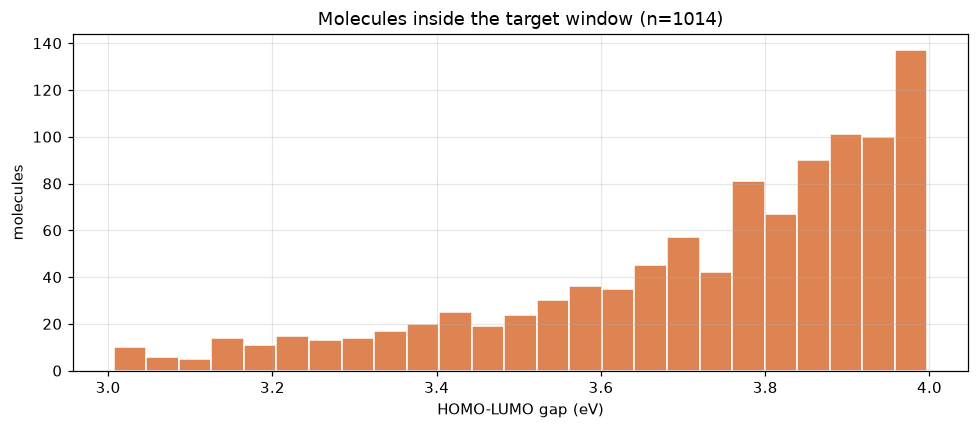

In [6]:
win = qm9[in_window].copy()

fig, ax = plt.subplots(figsize=(9, 4))
ax.hist(win["gap_ev"], bins=25, color="#DD8452", edgecolor="white")
ax.set(xlabel="HOMO-LUMO gap (eV)", ylabel="molecules",
       title=f"Molecules inside the target window (n={len(win)})")
plt.tight_layout()

### Composition of the window

Low-gap QM9 molecules are enriched in **zwitterions**, which are poor seeds: they complicate
xTB charge handling and are not the chemistry the benchmark is aiming at.

Net charge is the wrong test for this - a zwitterion's `+1` and `-1` cancel to zero. The
check below counts molecules carrying *any* formal charge.

In [7]:
def net_charge(m):
    return sum(a.GetFormalCharge() for a in m.GetAtoms())

def n_charged_atoms(m):
    return sum(a.GetFormalCharge() != 0 for a in m.GetAtoms())

win["mol"] = win["smiles"].map(Chem.MolFromSmiles)
win = win[win["mol"].notna()].copy()
win["net_charge"] = win["mol"].map(net_charge)
win["charged_atoms"] = win["mol"].map(n_charged_atoms)
win["uncharged"] = win["charged_atoms"] == 0          # no formal charges at all
win["zwitterion"] = (win["charged_atoms"] > 0) & (win["net_charge"] == 0)
win["heavy"] = win["mol"].map(lambda m: m.GetNumHeavyAtoms())

print(f"in window:            {len(win)}")
print(f"  net charge == 0:    {(win['net_charge'] == 0).sum()}   <- all of them")
print(f"  no formal charges:  {win['uncharged'].sum()}")
print(f"  zwitterions:        {win['zwitterion'].sum()}")
print(f"\nheavy-atom counts (no formal charges):")
print(win.loc[win['uncharged'], 'heavy'].value_counts().sort_index().to_string())

in window:            1014
  net charge == 0:    1014   <- all of them
  no formal charges:  820
  zwitterions:        194

heavy-atom counts (no formal charges):
heavy
6      2
7      7
8     67
9    744


## Gap versus molecular size

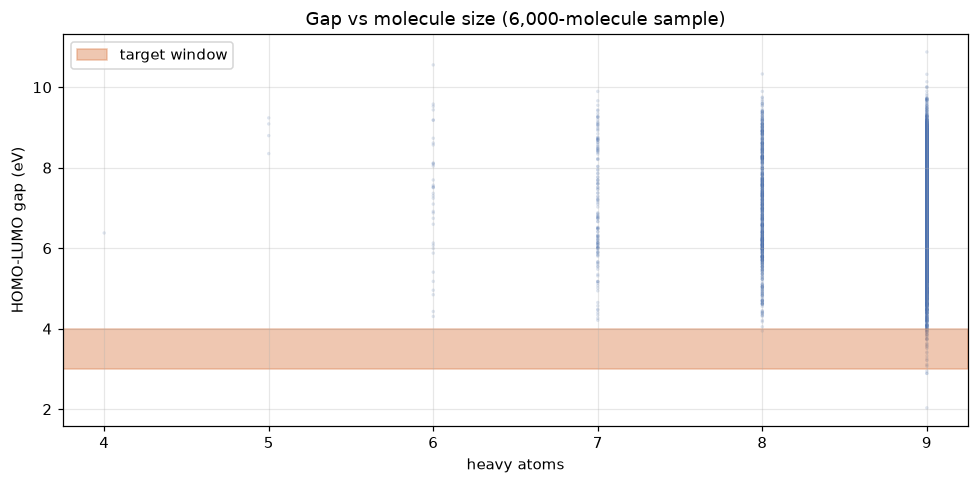

In [8]:
sample = qm9.sample(6000, random_state=0)
sample = sample.assign(heavy=sample["smiles"].map(
    lambda s: Chem.MolFromSmiles(s).GetNumHeavyAtoms() if Chem.MolFromSmiles(s) else None))

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.scatter(sample["heavy"], sample["gap_ev"], s=5, alpha=0.18,
           color="#4C72B0", edgecolors="none")
ax.axhspan(TARGET_LO, TARGET_HI, color="#DD8452", alpha=0.45, label="target window")
ax.set(xlabel="heavy atoms", ylabel="HOMO-LUMO gap (eV)",
       title="Gap vs molecule size (6,000-molecule sample)")
ax.legend()
plt.tight_layout()

---

# Chemistry of the target window

What the pool of candidate seeds actually contains. Zwitterions are excluded (see above):
uncharged molecules only.

In [9]:
from rdkit.Chem import Draw
from rdkit.Chem.Scaffolds import MurckoScaffold

pool = win[win["uncharged"]].reset_index(drop=True)
print(f"{len(pool)} uncharged molecules in {TARGET_LO}-{TARGET_HI} eV")

820 uncharged molecules in 3.0-4.0 eV


## What chemistry is in there

Bemis-Murcko scaffolds strip side chains and report the ring framework, which is a more
chemically readable summary than a cluster id.

In [10]:
pool["scaffold"] = [MurckoScaffold.MurckoScaffoldSmiles(mol=m) for m in pool["mol"]]
scaf = pool["scaffold"].value_counts()
print(f"{len(scaf)} distinct Murcko scaffolds "
      f"({(pool['scaffold'] == '').sum()} molecules are acyclic, i.e. empty scaffold)\n")
scaf.head(15).to_frame("molecules")

331 distinct Murcko scaffolds (92 molecules are acyclic, i.e. empty scaffold)



,molecules
scaffold,
,92
O=C1C=CCC1=O,29
O=C1CCCC1=O,26
N=c1cncc[nH]1,25
N=c1nccn[nH]1,25
N=c1cncco1,24
N=c1cncn[nH]1,19
O=c1cncco1,17
C1CN1,16


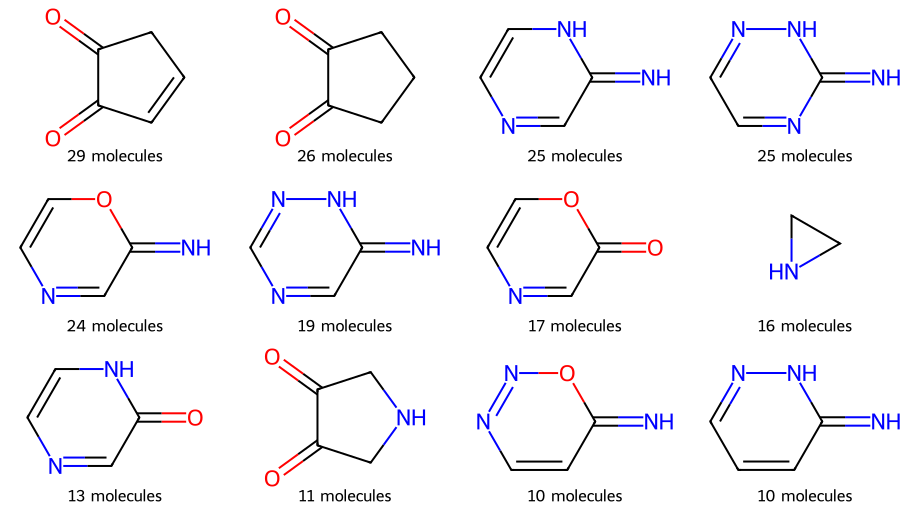

In [11]:
ring = pool[pool["scaffold"] != ""]
top = ring["scaffold"].value_counts().head(12)
Draw.MolsToGridImage([Chem.MolFromSmiles(s) for s in top.index],
                     legends=[f"{n} molecules" for n in top.values],
                     molsPerRow=4, subImgSize=(230, 170))

---

# Chemical filter

Clustering organises whatever it is given, so unsuitable structures are removed first.
Three families dominate the window and none make good seeds:

| | pattern | why it is dropped |
| --- | --- | --- |
| exocyclic-imine tautomers | `[#6;R]=[NX2;!R]` | QM9 wrote `N=c1cncc[nH]1`, where a chemist draws the amino form `Nc1cnccn1`. Rewriting them would invalidate the QM9 gap label, which was computed for the tautomer as written, so they are dropped rather than corrected. |
| three-membered rings | ring size 3 | aziridines and epoxides: strained and reactive |
| alpha-diketones | `[CX3](=O)[CX3]=O` | adjacent carbonyls hydrate and oxidise readily |

In [12]:
import sys
sys.path.insert(0, "../src")
from molcurator.chem.convert import is_implausible   # the rule GENERATE applies to candidates

FILTERS = {
    "exocyclic imine": Chem.MolFromSmarts("[#6;R]=[NX2;!R]"),
    "alpha-dione":     Chem.MolFromSmarts("[CX3](=O)[CX3]=O"),
}

def flags(m):
    f = {name: m.HasSubstructMatch(sm) for name, sm in FILTERS.items()}
    f["3-ring"] = any(len(r) == 3 for r in m.GetRingInfo().AtomRings())
    # is_implausible: rings > 8, small rings fused to another, triple bonds inside rings,
    # cumulated double bonds. GENERATE rejects candidates on this, so seeds must pass too.
    f["implausible"] = is_implausible(Chem.MolToSmiles(m))
    f["acyclic"] = m.GetRingInfo().NumRings() == 0      # want chromophores, not chains
    return f

flag_df = pd.DataFrame([flags(m) for m in pool["mol"]], index=pool.index)
flag_df["any"] = flag_df.any(axis=1)

print(f"pool before filter: {len(pool)}\n")
for col in ["exocyclic imine", "alpha-dione", "3-ring", "implausible", "acyclic"]:
    print(f"  {col:<18} {flag_df[col].sum():>4}")
print(f"  {'-- any of these':<18} {flag_df['any'].sum():>4}  (overlaps counted once)")

clean = pool[~flag_df["any"]].reset_index(drop=True)
print(f"\npool after filter:  {len(clean)}")

pool before filter: 820

  exocyclic imine     237
  alpha-dione         285
  3-ring               97
  implausible          97
  acyclic              92
  -- any of these     594  (overlaps counted once)

pool after filter:  226


## What survived

In [13]:
print(f"gap range {clean['gap_ev'].min():.2f} - {clean['gap_ev'].max():.2f} eV, "
      f"median {clean['gap_ev'].median():.2f}")
print(f"heavy atoms: {clean['heavy'].min()} - {clean['heavy'].max()}\n")

clean_scaf = clean["scaffold"].value_counts()
print(f"{len(clean_scaf)} distinct Murcko scaffolds "
      f"({(clean['scaffold'] == '').sum()} acyclic)")
clean_scaf.head(12).to_frame("molecules")

gap range 3.01 - 3.99 eV, median 3.82
heavy atoms: 6 - 9

147 distinct Murcko scaffolds (0 acyclic)


,molecules
scaffold,
O=c1cncco1,17
O=c1cncc[nH]1,13
c1cc2nnoc2[nH]1,7
O=c1cncn[nH]1,5
c1cc2nnoc2o1,5
O=c1ccccnc1,5
O=C1C=CC(=O)C1,4
c1cnncn1,3
O=c1cccncc1,3


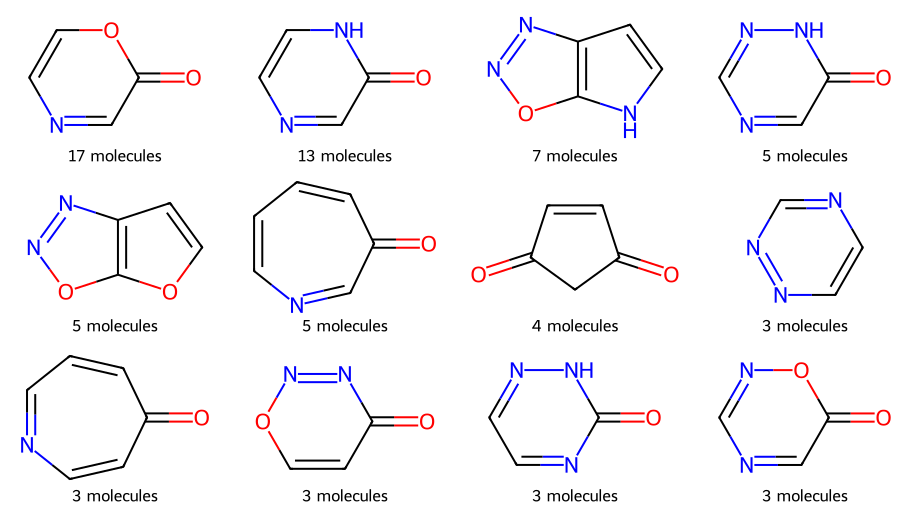

In [14]:
top = clean[clean["scaffold"] != ""]["scaffold"].value_counts().head(12)
Draw.MolsToGridImage([Chem.MolFromSmiles(s) for s in top.index],
                     legends=[f"{n} molecules" for n in top.values],
                     molsPerRow=4, subImgSize=(230, 170))

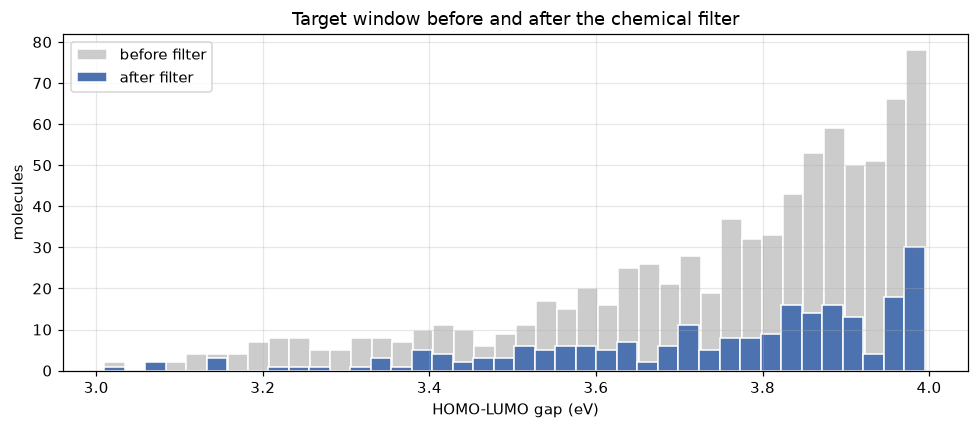

In [15]:
fig, ax = plt.subplots(figsize=(9, 4))
ax.hist(pool["gap_ev"], bins=40, color="#CCCCCC", edgecolor="white", label="before filter")
ax.hist(clean["gap_ev"], bins=40, color="#4C72B0", edgecolor="white", label="after filter")
ax.set(xlabel="HOMO-LUMO gap (eV)", ylabel="molecules",
       title="Target window before and after the chemical filter")
ax.legend()
plt.tight_layout()

---

# Selecting 10 seeds

Three constraints, applied together:

1. **Spread across the window.** Two seeds from each 0.2 eV bin, so the run does not start
   entirely at one edge. The filtered pool is skewed towards 3.8-4.0 eV, so without this the
   picks would bunch there.
2. **Distinct ring frameworks.** No two seeds share a Murcko scaffold.
3. **Representative, not extreme.** Scaffolds are taken most-common-first, and within a
   scaffold the **medoid** molecule is chosen. A MaxMin diversity pick does the opposite:
   it maximises dissimilarity, so it surfaces each bin's strangest structure - in an earlier
   run it returned polycyclic cages and a nine-membered ring containing a triple bond.

In [16]:
from rdkit import DataStructs
from rdkit.Chem import rdFingerprintGenerator

BIN_WIDTH, PER_BIN = 0.2, 2
mfpgen = rdFingerprintGenerator.GetMorganGenerator(radius=2, fpSize=2048)

# How common each scaffold is across the whole clean pool. Taking common scaffolds gives
# representative chemistry; MaxMin does the opposite and surfaces the outliers.
scaffold_freq = clean["scaffold"].value_counts()

def medoid(group):
    """The most central molecule of a group: highest mean similarity to the others."""
    if len(group) == 1:
        return group.index[0]
    fps = [mfpgen.GetFingerprint(m) for m in group["mol"]]
    means = [sum(DataStructs.BulkTanimotoSimilarity(f, fps)) / len(fps) for f in fps]
    return group.index[means.index(max(means))]

picked, used = [], set()
edges = [round(TARGET_LO + BIN_WIDTH * k, 2)
         for k in range(int(round((TARGET_HI - TARGET_LO) / BIN_WIDTH)))]

for lo in edges:
    b = clean[clean["gap_ev"].between(lo, lo + BIN_WIDTH, inclusive="left")]
    if b.empty:
        continue
    order = sorted(set(b["scaffold"]) - used, key=lambda s: -scaffold_freq.get(s, 0))
    taken = 0
    for scaf in order:
        if taken == PER_BIN:
            break
        used.add(scaf)
        picked.append(clean.loc[medoid(b[b["scaffold"] == scaf])])
        taken += 1
    print(f"{lo:.1f}-{lo + BIN_WIDTH:.1f} eV: {len(b):>3} available, "
          f"{len(set(b['scaffold'])):>3} scaffolds, took {taken}")

seeds = pd.DataFrame(picked).sort_values("gap_ev").reset_index(drop=True)
print(f"\nselected {len(seeds)} seeds, {seeds['scaffold'].nunique()} distinct scaffolds")

3.0-3.2 eV:   6 available,   6 scaffolds, took 2
3.2-3.4 eV:  13 available,  12 scaffolds, took 2
3.4-3.6 eV:  35 available,  29 scaffolds, took 2
3.6-3.8 eV:  53 available,  43 scaffolds, took 2
3.8-4.0 eV: 119 available,  84 scaffolds, took 2

selected 10 seeds, 10 distinct scaffolds


## The selected seeds

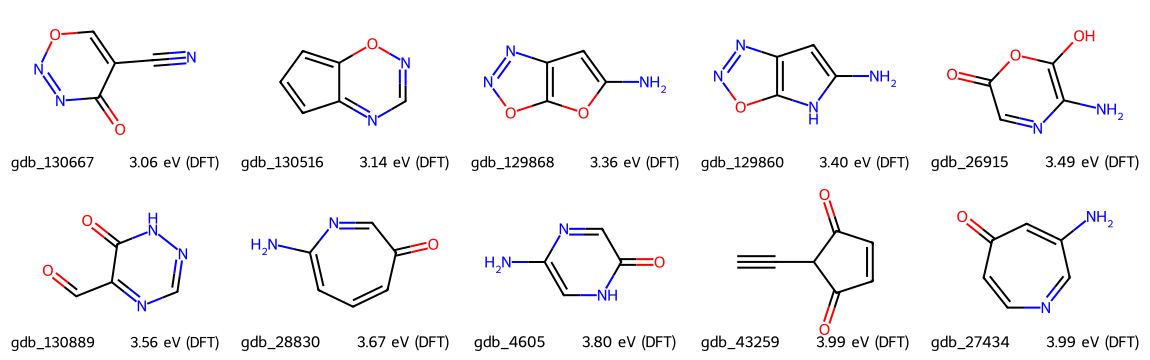

In [17]:
Draw.MolsToGridImage(
    list(seeds["mol"]),
    legends=[f"{r.mol_id} · {r.gap_ev:.2f} eV (DFT)" for r in seeds.itertuples()],
    molsPerRow=5, subImgSize=(230, 180))

## Write `data/seeds/homo_lumo.csv`

The SMILES the agent seeds with, the QM9 id so the DFT label can be traced back, and the
scaffold. No xTB values: these seeds are for generating and testing candidates, and the xTB
numbers belong to PREDICT rather than to seed selection.

In [18]:
out = seeds[["smiles", "mol_id", "gap_ev", "heavy", "scaffold"]].copy()
out.columns = ["smiles", "mol_id", "qm9_dft_gap_ev", "heavy_atoms", "murcko_scaffold"]
out["source"] = "QM9"
out["qm9_dft_gap_ev"] = out["qm9_dft_gap_ev"].round(4)
out.to_csv("../data/seeds/homo_lumo.csv", index=False)
print(out.to_string(index=False))

              smiles     mol_id  qm9_dft_gap_ev  heavy_atoms murcko_scaffold source
     O=C1N=NOC=C1C#N gdb_130667          3.0640            9      O=c1cconn1    QM9
      c1cc-2ncnoc2c1 gdb_130516          3.1402            9  c1cc2ncnoc-2c1    QM9
  NC1=CC2=C(ON=N2)O1 gdb_129868          3.3579            9    c1cc2nnoc2o1    QM9
  NC1=CC2=C(N1)ON=N2 gdb_129860          3.3987            9 c1cc2nnoc2[nH]1    QM9
  c1c(=O)oc(c(n1)N)O  gdb_26915          3.4912            9      O=c1cncco1    QM9
c1nc(c(=O)[nH]n1)C=O gdb_130889          3.5592            9   O=c1cncn[nH]1    QM9
    c1cc(=O)cnc(c1)N  gdb_28830          3.6708            9     O=c1ccccnc1    QM9
  c1c(ncc(=O)[nH]1)N   gdb_4605          3.7960            8   O=c1cncc[nH]1    QM9
   O=C1C=CC(=O)C1C#C  gdb_43259          3.9946            9  O=C1C=CC(=O)C1    QM9
      c1cncc(cc1=O)N  gdb_27434          3.9946            9     O=c1cccncc1    QM9


## Takeaways

- QM9 gaps are centred near **6.8 eV** (median 6.79, s.d. 1.29). The 3.0-4.0 eV target is
  a lower tail holding 1,014 molecules, 0.76% of the dataset. Widening the window from
  3.0-3.5 to 3.0-4.0 grew the pool from 181 to 1,014 - a 5.6x gain, because the
  distribution rises steeply across 3.5-4.0 eV.
- Every molecule in the window has **net charge zero**, but 194 of the 1,014 carry formal
  charges and are zwitterions. Net charge is a misleading filter here; screen on whether
  any atom is charged. That leaves **820** uncharged candidates to select seeds from.
- Nearly all window molecules (744 of 820) sit at QM9's **size ceiling of 9 heavy atoms** - a small gap
  needs as much conjugation as the dataset allows. That matters for `GENERATE`, whose
  candidates are capped at 15 heavy atoms and bounded to 0.5-1.5x the parent size.
- Low gaps in a saturated-molecule dataset come mainly from carbonyl and imine chains, so
  the window's chemistry skews toward polycarbonyls and amidines rather than the aromatic
  chromophores a chemist would reach for. Seed selection should filter on structure, not
  on the gap value alone.
- A chemical filter is needed before the pool is usable. Exocyclic-imine tautomers,
  alpha-diketones and three-membered rings account for **563 of the 820** uncharged
  molecules, leaving **257**.
- The filter removes low-gap molecules preferentially, because the alpha-diones were
  driving the small gaps. Of the 257 survivors only 41 fall in 3.0-3.5 eV and just 11
  below 3.25 eV, so the wider 3.0-4.0 eV window is what makes the pool workable.